# 🐼 Pandas — Les fonctions à connaître (aide-mémoire débutant)

**But de ce notebook :** faire le tour de **toutes les fonctions Pandas essentielles**, une par une,
avec du code **très simple** et **commenté ligne par ligne**, sur **nos propres jeux de données**.

On ne cherche pas à écrire du code "malin" : on cherche du code **qu'on comprend**.

### 📂 Nos 4 fichiers (dans le même dossier que ce notebook)

| Fichier | Contenu | Clé principale |
|---|---|---|
| `TIE.csv` | les **tiers** (clients) : type, sexe, date de naissance, langue... | `IDT_PI` |
| `TIE_ADR.csv` | les **adresses** des clients : nom, ville, e-mail, téléphone... | `IDT_PI` |
| `CTR.csv` | les **contrats** (comptes) : devise, état, solde, montant initial... | `IDT_AC` |
| `TIE_X_CTR.csv` | la **table de liaison** : quel client possède quel contrat | `IDT_PI` + `IDT_AC` |

⚠️ Particularité de nos fichiers : le séparateur est un **point-virgule `;`** et les valeurs
manquantes sont écrites avec un **point `.`** (héritage SAS).

### 🗺️ Sommaire

1. Importer Pandas
2. Lire un fichier : `read_csv`
3. Premier coup d'œil : `head`, `tail`, `shape`, `info`, `describe`...
4. Sélectionner des colonnes
5. Sélectionner des lignes : `loc`, `iloc`
6. Filtrer : conditions, `isin`, `between`, `query`
7. Trier : `sort_values`, `nlargest`
8. Compter : `value_counts`, `unique`, `nunique`
9. Valeurs manquantes : `isna`, `fillna`, `dropna`
10. Changer le type : `astype`, `to_datetime`, `to_numeric`
11. Créer / renommer / supprimer des colonnes
12. Travailler le texte : `.str`
13. Travailler les dates : `.dt`
14. Statistiques : `sum`, `mean`, `min`, `max`...
15. Regrouper : `groupby`, `agg`
16. Tableaux croisés : `pivot_table`, `crosstab`
17. Fusionner des tableaux : `merge`, `concat`
18. Doublons : `duplicated`, `drop_duplicates`
19. L'index : `set_index`, `reset_index`
20. Graphiques rapides : `.plot`
21. Sauvegarder : `to_csv`, `to_excel`
22. 📋 Récapitulatif + mini-défis

💡 **Astuce :** exécutez les cellules **dans l'ordre** avec `Maj + Entrée`.

## 1. Importer Pandas

Avant d'utiliser Pandas, il faut l'**importer**. Tout le monde l'appelle `pd` (c'est une convention).

In [5]:
import pandas as pd   # on importe Pandas et on lui donne le petit nom "pd"
import numpy as np    # NumPy sert parfois avec Pandas (par exemple np.where)

print(pd.__version__) # affiche la version de Pandas installée

2.3.0


## 2. Lire un fichier : `pd.read_csv()`

`pd.read_csv()` lit un fichier CSV et le transforme en **DataFrame** (un tableau avec des lignes
et des colonnes, comme une feuille Excel).

Les options utiles pour nos fichiers :
- `sep=";"` → les colonnes sont séparées par des points-virgules
- `na_values="."` → le point `.` veut dire "valeur manquante"
- `dtype={...}` → forcer une colonne en **texte** (sinon les zéros au début disparaissent : `"0029..."` deviendrait `29...`)

In [6]:
# Les contrats
ctr = pd.read_csv(
    "CTR.csv",                         # nom du fichier
    sep=";",                           # séparateur : point-virgule
    na_values=".",                     # le "." devient une valeur manquante (NaN)
    dtype={"REF_CTR_INN": str},        # on garde la référence en texte (zéros du début conservés)
)

# Les clients (tiers)
tie = pd.read_csv("TIE.csv", sep=";", na_values=".", dtype={"NUM_TIE": str})

# Les adresses des clients
adr = pd.read_csv("TIE_ADR.csv", sep=";", na_values=".", dtype={"NUM_TIE": str, "COD_PST": str})

# La liaison client <-> contrat
lien = pd.read_csv("TIE_X_CTR.csv", sep=";", na_values=".", dtype={"NUM_TIE": str, "REF_CTR_INN": str})

print("Fichiers chargés ✅")

Fichiers chargés ✅


💡 Autres fonctions de lecture à connaître (même principe) :
`pd.read_excel("fichier.xlsx")`, `pd.read_json("fichier.json")`, `pd.read_sql(requete, connexion)`.

## 3. Premier coup d'œil sur les données

Quand on ouvre un fichier, on commence **toujours** par le regarder.

| Fonction | À quoi ça sert |
|---|---|
| `df.head()` | les 5 premières lignes |
| `df.tail()` | les 5 dernières lignes |
| `df.sample()` | des lignes au hasard |
| `df.shape` | (nombre de lignes, nombre de colonnes) |
| `df.columns` | la liste des noms de colonnes |
| `df.dtypes` | le type de chaque colonne |
| `df.info()` | résumé complet : colonnes, types, valeurs non vides |
| `df.describe()` | statistiques des colonnes chiffrées |

In [7]:
ctr.head()      # affiche les 5 premières lignes (mettre un nombre : ctr.head(10))

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI
0,65500004701,0029862201102,2024-05-29,6,2025-12-10,2025-12-10,EUR,NaN,NaN,NaN,NaN
1,65500006391,0029912218433,2024-08-07,6,2025-02-05,2025-02-05,EUR,NaN,NaN,NaN,NaN
2,65500007774,0029922113324,2022-01-12,4,2022-01-12,NaN,EUR,NaN,NaN,NaN,NaN
3,65500008787,0029872222935,2025-01-07,4,2025-01-07,NaN,EUR,NaN,2025-10-31,NaN,NaN
4,65500014230,0029862237513,2025-01-18,6,2025-02-15,2025-02-15,EUR,NaN,NaN,NaN,NaN


In [8]:
ctr.tail(3)     # affiche les 3 dernières lignes

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI
197,65500491523,0025304103771,2026-01-09,4,2026-01-09,NaN,EUR,NaN,NaN,NaN,NaN
198,65500491571,0025244098277,2026-01-09,4,2026-01-09,NaN,EUR,NaN,NaN,NaN,NaN
199,65500491575,0025754099879,2026-01-09,4,2026-01-09,NaN,EUR,0.0,NaN,0.0,NaN


In [9]:
ctr.sample(3)   # affiche 3 lignes tirées au hasard

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI
155,65500451888,0090093430936,2018-03-12,4,2018-03-12,NaN,EUR,15348.7,2026-05-26,15348.7,NaN
121,65500303549,0029972192088,2021-10-27,4,2021-10-27,NaN,EUR,NaN,NaN,NaN,NaN
175,65500482863,0025594088284,2025-12-05,4,2025-12-05,NaN,EUR,0.0,2026-04-30,NaN,0.0


In [94]:
print(ctr.shape)      # (lignes, colonnes)
print(len(ctr))       # le nombre de lignes seulement
print(ctr.columns)    # les noms des colonnes


(200, 15)
200
Index(['IDT_AC', 'REF_CTR_INN', 'DAT_OUV_CTR', 'COD_ECV_CTR', 'DAT_ECV_CTR',
       'DAT_CLO_CTR', 'COD_DEV', 'SLD_CTR', 'DAT_MAJ_SLD', 'SLD_DSP',
       'MNT_INI', 'STATUT', 'TAILLE', 'ANNEE_OUV', 'DUREE_JOURS'],
      dtype='object')


In [11]:
ctr.dtypes      # le type de chaque colonne : int64 = entier, float64 = nombre à virgule, object = texte

IDT_AC           int64
REF_CTR_INN     object
DAT_OUV_CTR     object
COD_ECV_CTR      int64
DAT_ECV_CTR     object
DAT_CLO_CTR     object
COD_DEV         object
SLD_CTR        float64
DAT_MAJ_SLD     object
SLD_DSP        float64
MNT_INI        float64
dtype: object

In [12]:
ctr.info()      # résumé : nombre de valeurs NON vides et type pour chaque colonne

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   IDT_AC       200 non-null    int64  
 1   REF_CTR_INN  200 non-null    object 
 2   DAT_OUV_CTR  200 non-null    object 
 3   COD_ECV_CTR  200 non-null    int64  
 4   DAT_ECV_CTR  200 non-null    object 
 5   DAT_CLO_CTR  95 non-null     object 
 6   COD_DEV      200 non-null    object 
 7   SLD_CTR      63 non-null     float64
 8   DAT_MAJ_SLD  72 non-null     object 
 9   SLD_DSP      47 non-null     float64
 10  MNT_INI      40 non-null     float64
dtypes: float64(3), int64(2), object(6)
memory usage: 17.3+ KB


In [13]:
ctr.describe()  # nombre, moyenne, écart-type, min, quartiles, max des colonnes chiffrées

,IDT_AC,COD_ECV_CTR,SLD_CTR,SLD_DSP,MNT_INI
count,2.000000e+02,200.000000,63.000000,47.000000,40.000000
mean,6.550026e+10,4.950000,-11801.391905,997.404043,74767.107750
std,1.603949e+05,1.001255,44454.064711,4445.139150,108616.505305
min,6.550000e+10,4.000000,-201694.930000,-1961.690000,0.000000
25%,6.550012e+10,4.000000,0.000000,0.000000,3802.500000
50%,6.550023e+10,4.000000,0.000000,0.000000,19555.450000
75%,6.550042e+10,6.000000,0.000000,0.000000,162400.000000
max,6.550049e+10,6.000000,79156.240000,26168.600000,448500.000000


In [95]:
# Astuce : voir toutes les colonnes même si le tableau est large
pd.set_option("display.max_columns", None)   # None = pas de limite
adr.head(3)

,IDT_PI,NUM_TIE,NOM_TIE,PRN,ADR_LIG1,ADR_LIG2,ADR_LIG3,ADR_LIG4,ADR_LIG5,ADR_LIG6,NUM_TEL_DOM_INL,NUM_TEL_MOB_INL,ADR_EMA,NOM_VIL,COD_IDT_NTN,DAT_MAJ_ADR,LIB_TIT,COD_PST,COD_PAY_ISO,NOM_CMU_NAI,DOMAINE,ZONE
0,655010234,2500003178436,CEBBCACFZAAAFZTIER,NaN,CEBBCACFZAAAFZTIER,NaN,NaN,NaN,RUE DE L'ABRICOTIER 5,1000 BRUXELLES,NaN,NaN,PRO@FREE.BE,BRUXELLES,NaN,2025-11-24,NaN,1000,BE,NaN,FREE.BE,10
1,655010248,2500003178512,VIRJXBF,NTASEIJZR,M NTASEIJZR VIRJXBF,NaN,NaN,NaN,BOULEVARD DU ROI ALBERT II 2,1000 BRUXELLES,NaN,455677336.0,TTSAXL@E-I.COM,BRUXELLES,4.032897e+09,2025-11-24,Monsieur,1000,BE,LILLE,E-I.COM,10
2,655010249,2500003178544,JANSSENS,BART,M BART JANSSENS,NaN,NaN,NaN,WETSTRAAT 16,1000 BRUSSEL,NaN,468210388.0,BART.JANSSENS@GMAIL.COM,BRUSSEL,8.001258e+10,2026-01-09,Monsieur,1000,BE,BRUXELLES,GMAIL.COM,10


## 4. Sélectionner des colonnes

- **Une** colonne : `df["nom"]` → on obtient une **Series** (une seule colonne)
- **Plusieurs** colonnes : `df[["nom1", "nom2"]]` → attention aux **doubles crochets**, on obtient un DataFrame

In [97]:
ctr["COD_DEV"].head(2)            # une seule colonne : la devise

0    EUR
1    EUR
Name: COD_DEV, dtype: object

In [16]:
ctr[["IDT_AC", "COD_DEV", "SLD_CTR"]].head()   # plusieurs colonnes : double crochet [[ ]]

,IDT_AC,COD_DEV,SLD_CTR
0,65500004701,EUR,NaN
1,65500006391,EUR,NaN
2,65500007774,EUR,NaN
3,65500008787,EUR,NaN
4,65500014230,EUR,NaN


## 5. Sélectionner des lignes : `loc` et `iloc`

| | Signification | Exemple |
|---|---|---|
| `df.iloc[...]` | par **position** (0, 1, 2...) | `ctr.iloc[0]` = la 1ʳᵉ ligne |
| `df.loc[...]` | par **nom** (étiquette d'index, nom de colonne) | `ctr.loc[0, "COD_DEV"]` |

Avec `loc` on peut écrire `df.loc[lignes, colonnes]`.

In [117]:

# par libellé (ligne 0, colonne "COD_DEV")
ctr.loc[0, "COD_DEV"]



'EUR'

In [118]:
ctr.iloc[0:1]          # la première ligne (position 0)

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI,STATUT,TAILLE,ANNEE_OUV,DUREE_JOURS
0,65500004701,0029862201102,2024-05-29,6,2025-12-10,2025-12-10,EUR,NaN,NaN,NaN,NaN,CLOTURE,Inconnu,2024,560.0


In [18]:
ctr.iloc[0:3]        # les lignes de position 0, 1 et 2 (le 3 est exclu)

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI
0,65500004701,0029862201102,2024-05-29,6,2025-12-10,2025-12-10,EUR,NaN,NaN,NaN,NaN
1,65500006391,0029912218433,2024-08-07,6,2025-02-05,2025-02-05,EUR,NaN,NaN,NaN,NaN
2,65500007774,0029922113324,2022-01-12,4,2022-01-12,NaN,EUR,NaN,NaN,NaN,NaN


In [110]:
ctr.iloc[0:3, 0:2]   # 3 premières lignes, 2 premières colonnes

,IDT_AC,REF_CTR_INN
0,65500004701,0029862201102
1,65500006391,0029912218433
2,65500007774,0029922113324


In [120]:
ctr.loc[2, "IDT_AC"]                    # une seule case : ligne d'index 0, colonne COD_DEV

np.int64(65500007774)

In [112]:
ctr.loc[0:4, ["IDT_AC", "COD_DEV"]]      # lignes d'index 0 à 4 (4 INCLUS avec loc), 2 colonnes

,IDT_AC,COD_DEV
0,65500004701,EUR
1,65500006391,EUR
2,65500007774,EUR
3,65500008787,EUR
4,65500014230,EUR


## 6. Filtrer les lignes

On écrit une **condition** entre crochets : `df[ condition ]`.

| Opérateur | Sens |
|---|---|
| `==` / `!=` | égal / différent |
| `>` `<` `>=` `<=` | comparaisons |
| `&` | ET (mettre chaque condition entre parenthèses) |
| `\|` | OU |
| `~` | NON (inverse la condition) |

In [126]:
# Les contrats en dollars
ctr[ctr["DAT_ECV_CTR"] == "2025-12-10"]

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI,STATUT,TAILLE,ANNEE_OUV,DUREE_JOURS
0,65500004701,0029862201102,2024-05-29,6,2025-12-10,2025-12-10,EUR,NaN,NaN,NaN,NaN,CLOTURE,Inconnu,2024,560.0
5,65500016903,0029892298341,2024-05-29,6,2025-12-10,2025-12-10,EUR,NaN,2025-10-31,NaN,NaN,CLOTURE,Inconnu,2024,560.0


In [127]:
# Les contrats avec un solde supérieur à 1000
ctr[ctr["SLD_CTR"] > 10000]

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI,STATUT,TAILLE,ANNEE_OUV,DUREE_JOURS
72,65500163296,0029762182482,2021-07-23,4,2021-07-23,NaT,EUR,26168.60,2026-05-27,26168.6,NaN,OUVERT,Inconnu,2021,NaN
96,65500204394,0090080911729,2011-11-17,4,2018-11-25,NaT,EUR,79156.24,2026-05-27,NaN,NaN,OUVERT,Inconnu,2011,NaN
155,65500451888,0090093430936,2018-03-12,4,2018-03-12,NaT,EUR,15348.70,2026-05-26,15348.7,NaN,OUVERT,Inconnu,2018,NaN


In [132]:
# ET : contrats en EUR ET avec un solde positif  -> parenthèses obligatoires autour de chaque condition
pd = ctr[(ctr["COD_DEV"] == "EUR") & (ctr["SLD_CTR"] > 1000)]
pd

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI,STATUT,TAILLE,ANNEE_OUV,DUREE_JOURS
18,65500050418,0029282017114,2020-12-01,6,2024-08-01,2024-08-01,EUR,1219.68,2025-10-31,NaN,0.0,CLOTURE,Petit,2020,1339.0
48,65500115203,0090087852236,2009-09-02,4,2009-09-02,NaT,EUR,3718.53,2026-05-18,3718.53,NaN,OUVERT,Inconnu,2009,NaN
66,65500153407,0029762342182,2025-04-03,4,2025-04-03,NaT,EUR,3279.78,2026-05-15,3279.78,NaN,OUVERT,Inconnu,2025,NaN
72,65500163296,0029762182482,2021-07-23,4,2021-07-23,NaT,EUR,26168.60,2026-05-27,26168.60,NaN,OUVERT,Inconnu,2021,NaN
96,65500204394,0090080911729,2011-11-17,4,2018-11-25,NaT,EUR,79156.24,2026-05-27,NaN,NaN,OUVERT,Inconnu,2011,NaN
155,65500451888,0090093430936,2018-03-12,4,2018-03-12,NaT,EUR,15348.70,2026-05-26,15348.70,NaN,OUVERT,Inconnu,2018,NaN


In [133]:
# OU : contrats en USD OU en NOK
ctr[(ctr["COD_DEV"] == "USD") | (ctr["DAT_OUV_CTR"] == "2018-02-23")]

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI,STATUT,TAILLE,ANNEE_OUV,DUREE_JOURS
6,65500017438,0029882152002,2020-12-09,4,2020-12-09,NaT,USD,2.82,2025-02-12,2.82,NaN,OUVERT,Inconnu,2020,NaN
117,65500292479,0029662256695,2023-02-06,6,2023-05-05,2023-05-05,USD,NaN,NaN,NaN,NaN,CLOTURE,Inconnu,2023,88.0
153,65500451620,0090093422949,2018-02-23,6,2025-12-03,2025-12-03,USD,0.00,2021-01-13,0.00,NaN,CLOTURE,Inconnu,2018,2840.0
154,65500451621,0090093422951,2018-02-23,6,2025-04-11,2025-04-11,USD,0.00,2025-04-11,0.00,NaN,CLOTURE,Inconnu,2018,2604.0
166,65500477169,0029412264634,2023-04-03,6,2023-11-06,2023-11-06,USD,NaN,NaN,NaN,NaN,CLOTURE,Inconnu,2023,217.0


In [134]:
# .isin([...]) : plus simple que plusieurs OU -> la valeur est-elle dans la liste ?
ctr[ctr["COD_DEV"].isin(["USD", "NOK", "AUD"])]

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI,STATUT,TAILLE,ANNEE_OUV,DUREE_JOURS
6,65500017438,0029882152002,2020-12-09,4,2020-12-09,NaT,USD,2.82,2025-02-12,2.82,NaN,OUVERT,Inconnu,2020,NaN
10,65500022341,0029102023089,2020-01-23,6,2020-04-24,2020-04-24,AUD,NaN,2025-10-31,NaN,NaN,CLOTURE,Inconnu,2020,92.0
103,65500248622,0029352012409,2020-01-23,6,2020-04-24,2020-04-24,NOK,NaN,NaN,NaN,NaN,CLOTURE,Inconnu,2020,92.0
117,65500292479,0029662256695,2023-02-06,6,2023-05-05,2023-05-05,USD,NaN,NaN,NaN,NaN,CLOTURE,Inconnu,2023,88.0
153,65500451620,0090093422949,2018-02-23,6,2025-12-03,2025-12-03,USD,0.00,2021-01-13,0.00,NaN,CLOTURE,Inconnu,2018,2840.0
154,65500451621,0090093422951,2018-02-23,6,2025-04-11,2025-04-11,USD,0.00,2025-04-11,0.00,NaN,CLOTURE,Inconnu,2018,2604.0
166,65500477169,0029412264634,2023-04-03,6,2023-11-06,2023-11-06,USD,NaN,NaN,NaN,NaN,CLOTURE,Inconnu,2023,217.0


In [27]:
# ~ : le contraire -> tous les contrats qui ne sont PAS en euros
ctr[~(ctr["COD_DEV"] == "EUR")]

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI
6,65500017438,0029882152002,2020-12-09,4,2020-12-09,NaN,USD,2.82,2025-02-12,2.82,NaN
10,65500022341,0029102023089,2020-01-23,6,2020-04-24,2020-04-24,AUD,NaN,2025-10-31,NaN,NaN
103,65500248622,0029352012409,2020-01-23,6,2020-04-24,2020-04-24,NOK,NaN,NaN,NaN,NaN
117,65500292479,0029662256695,2023-02-06,6,2023-05-05,2023-05-05,USD,NaN,NaN,NaN,NaN
153,65500451620,0090093422949,2018-02-23,6,2025-12-03,2025-12-03,USD,0.00,2021-01-13,0.00,NaN
154,65500451621,0090093422951,2018-02-23,6,2025-04-11,2025-04-11,USD,0.00,2025-04-11,0.00,NaN
166,65500477169,0029412264634,2023-04-03,6,2023-11-06,2023-11-06,USD,NaN,NaN,NaN,NaN


In [138]:
# .between(a, b) : valeur comprise entre a et b (bornes incluses)
ctr[ctr["SLD_CTR"].between(1000, 1300)]

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI,STATUT,TAILLE,ANNEE_OUV,DUREE_JOURS
18,65500050418,0029282017114,2020-12-01,6,2024-08-01,2024-08-01,EUR,1219.68,2025-10-31,NaN,0.0,CLOTURE,Petit,2020,1339.0


In [29]:
# .query("...") : écrire le filtre comme une phrase (pratique et lisible)
ctr.query("COD_DEV == 'EUR' and MNT_INI > 100000")

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI
56,65500127184,0029552184555,2021-07-02,4,2021-10-29,NaN,EUR,0.00,2026-04-30,NaN,162500.0
59,65500136358,0029612114154,2022-02-11,4,2022-05-25,NaN,EUR,-174000.00,2025-12-02,0.0,174000.0
75,65500166207,0029812164770,2021-01-07,6,2024-10-08,2024-10-08,EUR,0.00,2025-12-05,0.0,181500.0
81,65500173470,0029772130282,2022-09-05,4,2022-12-09,NaN,EUR,0.00,2026-04-30,NaN,162400.0
84,65500182205,0029472187836,2021-07-02,4,2021-10-29,NaN,EUR,-129247.05,2026-03-31,0.0,162500.0
115,65500282945,0029682136513,2022-09-05,4,2022-12-09,NaN,EUR,-162400.00,2025-12-02,0.0,162400.0
119,65500296996,0029662114606,2022-02-11,4,2022-05-25,NaN,EUR,0.00,2026-04-30,NaN,174000.0
126,65500317463,0090097367158,2015-09-15,4,2021-04-12,NaN,EUR,0.00,2026-04-30,NaN,448500.0
128,65500327875,0090097368687,2018-07-04,4,2021-02-23,NaN,EUR,0.00,2026-04-30,NaN,282000.0
138,65500380735,0090095198742,2018-07-16,4,2018-07-16,NaN,EUR,-201694.93,2026-03-31,0.0,282000.0


In [30]:
# Filtrer sur du texte : les adresses dont la ville contient "BRUX"
adr[adr["NOM_VIL"].str.contains("BRUX", na=False)]   # na=False : ignore les villes vides

,IDT_PI,NUM_TIE,NOM_TIE,PRN,ADR_LIG1,ADR_LIG2,ADR_LIG3,ADR_LIG4,ADR_LIG5,ADR_LIG6,NUM_TEL_DOM_INL,NUM_TEL_MOB_INL,ADR_EMA,NOM_VIL,COD_IDT_NTN,DAT_MAJ_ADR,LIB_TIT,COD_PST,COD_PAY_ISO,NOM_CMU_NAI
0,655010234,2500003178436,CEBBCACFZAAAFZTIER,NaN,CEBBCACFZAAAFZTIER,NaN,NaN,NaN,RUE DE L'ABRICOTIER 5,1000 BRUXELLES,NaN,NaN,PRO@FREE.BE,BRUXELLES,NaN,24NOV2025,NaN,1000,BE,NaN
1,655010248,2500003178512,VIRJXBF,NTASEIJZR,M NTASEIJZR VIRJXBF,NaN,NaN,NaN,BOULEVARD DU ROI ALBERT II 2,1000 BRUXELLES,NaN,455677336.0,TTSAXL@E-I.COM,BRUXELLES,4.032897e+09,24NOV2025,Monsieur,1000,BE,LILLE
3,655010254,2500003178588,FNLLTOKQT,OUOWQVIAYXRRUM,M OUOWQVIAYXRRUM FNLLTOKQT,NaN,NaN,NaN,BOULEVARD DU ROI ALBERT II 2,1000 BRUXELLES,NaN,455858667.0,AXQNLXS@E-I.COM,BRUXELLES,1.051888e+09,25NOV2025,Monsieur,1000,BE,BRUXELLES
4,655010256,2500003178678,KTFSJB,YSENDQZUCLU,M YSENDQZUCLU KTFSJB,NaN,NaN,NaN,BOULEVARD DU ROI ALBERT II 2,1000 BRUXELLES,NaN,455835778.0,ATZAOTCHSEPOHDMTMFB@E-I.COM,BRUXELLES,7.501301e+10,26NOV2025,Monsieur,1000,BE,BRUXELLES
5,655010259,2500003178748,QAFOHR,XWOSSHYHQLFRFVUP,MME XWOSSHYHQLFRFVUP QAFOHR,NaN,NaN,NaN,BOULEVARD DU ROI ALBERT II 2,1000 BRUXELLES,NaN,470912409.0,OOESUCCCNWBNHAC@E-I.COM,BRUXELLES,9.807228e+10,27NOV2025,Madame,1000,BE,BRUXELLES
10,655010285,2900000003194,JEANNE,SANTU,M SANTU JEANNE,NaN,NaN,NaN,AVENUE DES PUITS,1120 BRUXELLES,NaN,422078688.0,OIYGTIMS.XR7P.3SW2@39Y4.TEST,BRUXELLES,7.302128e+10,24NOV2018,Monsieur,1120,BE,IXELLES
21,655010322,2900000007592,TURGEON,MOIRA,GUHF. MOIRA DE NOA,NaN,NaN,NaN,BOULEVARD DU ROI ALBERT II 2,1000 BRUXELLES,NaN,455877777.0,XVJUHUDRPUOO@E-I.COM,BRUXELLES,7.003188e+10,04DEC2025,Mevrouw,1000,BE,GENT
83,655010562,2900000038505,S'HUFSD,LIYA,MME LIYA S'HUFSD,NaN,NaN,NaN,BOULEVARD DE LA CHAPELLE,1070 BRUXELLES,NaN,422032733.0,FW2FS0Z@SYNT.TEST,BRUXELLES,8.112046e+10,22OCT2020,Madame,1070,BE,KIGALI


## 7. Trier

- `sort_values("colonne")` → trie selon une colonne (croissant par défaut)
- `ascending=False` → ordre décroissant
- `nlargest(n, "col")` / `nsmallest(n, "col")` → les n plus grands / plus petits

In [170]:
ctr.sort_values("MNT_INI").head()                    # du plus petit au plus grand montant

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI,STATUT,TAILLE,ANNEE_OUV,DUREE_JOURS
9,65500021862,0029222189161,2021-07-29,6,2024-07-06,2024-07-06,EUR,0.00,2025-10-31,NaN,0.0,CLOTURE,Petit,2021,1073.0
14,65500033462,0029242185041,2021-09-01,4,2021-09-01,NaT,EUR,0.00,2025-10-31,NaN,0.0,OUVERT,Petit,2021,NaN
32,65500094550,0029522240130,2022-11-30,4,2022-11-30,NaT,EUR,0.00,2025-10-31,NaN,0.0,OUVERT,Petit,2022,NaN
18,65500050418,0029282017114,2020-12-01,6,2024-08-01,2024-08-01,EUR,1219.68,2025-10-31,NaN,0.0,CLOTURE,Petit,2020,1339.0
134,65500356635,0090089182848,2009-09-22,6,2010-10-15,2010-10-15,EUR,0.00,2025-11-28,0.0,0.0,CLOTURE,Petit,2009,388.0


In [171]:
ctr.sort_values("MNT_INI", ascending=False).head()   # du plus grand au plus petit

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI,STATUT,TAILLE,ANNEE_OUV,DUREE_JOURS
126,65500317463,0090097367158,2015-09-15,4,2021-04-12,NaT,EUR,0.00,2026-04-30,NaN,448500.0,OUVERT,Gros,2015,NaN
140,65500385545,0090095182421,2015-09-15,6,2024-10-08,2024-10-08,EUR,0.00,2025-12-05,0.0,325000.0,CLOTURE,Gros,2015,3311.0
128,65500327875,0090097368687,2018-07-04,4,2021-02-23,NaT,EUR,0.00,2026-04-30,NaN,282000.0,OUVERT,Gros,2018,NaN
138,65500380735,0090095198742,2018-07-16,4,2018-07-16,NaT,EUR,-201694.93,2026-03-31,0.0,282000.0,OUVERT,Gros,2018,NaN
75,65500166207,0029812164770,2021-01-07,6,2024-10-08,2024-10-08,EUR,0.00,2025-12-05,0.0,181500.0,CLOTURE,Gros,2021,1370.0


In [172]:
# Trier sur 2 colonnes : d'abord la devise, puis le solde
ctr.sort_values(["COD_DEV", "SLD_CTR","IDT_AC"]).head(2)

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI,STATUT,TAILLE,ANNEE_OUV,DUREE_JOURS
10,65500022341,0029102023089,2020-01-23,6,2020-04-24,2020-04-24,AUD,NaN,2025-10-31,NaN,NaN,CLOTURE,Inconnu,2020,92.0
138,65500380735,0090095198742,2018-07-16,4,2018-07-16,NaT,EUR,-201694.93,2026-03-31,0.0,282000.0,OUVERT,Gros,2018,NaN


In [173]:
ctr.nlargest(3, "MNT_INI")     # les 3 plus gros montants initiaux

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI,STATUT,TAILLE,ANNEE_OUV,DUREE_JOURS
126,65500317463,0090097367158,2015-09-15,4,2021-04-12,NaT,EUR,0.0,2026-04-30,NaN,448500.0,OUVERT,Gros,2015,NaN
140,65500385545,0090095182421,2015-09-15,6,2024-10-08,2024-10-08,EUR,0.0,2025-12-05,0.0,325000.0,CLOTURE,Gros,2015,3311.0
128,65500327875,0090097368687,2018-07-04,4,2021-02-23,NaT,EUR,0.0,2026-04-30,NaN,282000.0,OUVERT,Gros,2018,NaN


In [174]:
ctr.nsmallest(3, "SLD_DSP")     # les 3 plus petits soldes disponibles (les plus négatifs)

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI,STATUT,TAILLE,ANNEE_OUV,DUREE_JOURS
46,65500110463,0090087993875,2014-10-15,4,2014-10-15,NaT,EUR,-1961.69,2026-05-07,-1961.69,NaN,OUVERT,Inconnu,2014,NaN
136,65500368081,0090092127258,2014-10-15,4,2014-10-15,NaT,EUR,0.00,2025-12-31,-1961.69,3210.0,OUVERT,Petit,2014,NaN
169,65500477817,0025784077205,2025-11-28,4,2025-11-28,NaT,EUR,-265.97,2026-05-11,-265.97,NaN,OUVERT,Inconnu,2025,NaN


## 8. Compter les valeurs

| Fonction | Résultat |
|---|---|
| `.value_counts()` | combien de fois apparaît chaque valeur |
| `.unique()` | la liste des valeurs différentes |
| `.nunique()` | le **nombre** de valeurs différentes |
| `.count()` | le nombre de valeurs **non vides** |

In [175]:
ctr["COD_DEV"].value_counts()                    # nombre de contrats par devise

COD_DEV
EUR    193
USD      5
AUD      1
NOK      1
Name: count, dtype: int64

In [176]:
ctr["COD_DEV"].value_counts(normalize=True)      
# calculer la proportion (ou le pourcentage) de chaque valeur unique présente dans la colonne

COD_DEV
EUR    0.965
USD    0.025
AUD    0.005
NOK    0.005
Name: proportion, dtype: float64

In [177]:
print(tie["COD_SEX"].unique())    
# les valeurs différentes de la colonne sexe
print(tie["COD_SEX"].nunique())  
# combien de valeurs différentes
print(ctr["SLD_CTR"].count())     
# combien de soldes sont remplis

[nan 'M' 'F']
2
63


## 9. Les valeurs manquantes (NaN)

Une case vide s'appelle **NaN** ("Not a Number"). Nos `.` ont été transformés en NaN à la lecture.

| Fonction | Rôle |
|---|---|
| `.isna()` | `True` si la case est vide |
| `.notna()` | `True` si la case est remplie |
| `.isna().sum()` | nombre de cases vides par colonne |
| `.fillna(valeur)` | remplace les vides par une valeur |
| `.dropna()` | supprime les lignes qui ont des vides |

In [178]:
ctr.isna().sum()          # nombre de valeurs manquantes dans chaque colonne

IDT_AC           0
REF_CTR_INN      0
DAT_OUV_CTR      0
COD_ECV_CTR      0
DAT_ECV_CTR      0
DAT_CLO_CTR    105
COD_DEV          0
SLD_CTR        137
DAT_MAJ_SLD    128
SLD_DSP        153
MNT_INI        160
STATUT           0
TAILLE           0
ANNEE_OUV        0
DUREE_JOURS    105
dtype: int64

In [179]:
# Les contrats encore ouverts : pas de date de clôture
ctr[ctr["DAT_CLO_CTR"].isna()].head()

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI,STATUT,TAILLE,ANNEE_OUV,DUREE_JOURS
2,65500007774,0029922113324,2022-01-12,4,2022-01-12,NaT,EUR,NaN,NaN,NaN,NaN,OUVERT,Inconnu,2022,NaN
3,65500008787,0029872222935,2025-01-07,4,2025-01-07,NaT,EUR,NaN,2025-10-31,NaN,NaN,OUVERT,Inconnu,2025,NaN
6,65500017438,0029882152002,2020-12-09,4,2020-12-09,NaT,USD,2.82,2025-02-12,2.82,NaN,OUVERT,Inconnu,2020,NaN
13,65500033145,0029252120420,2022-08-23,4,2022-08-23,NaT,EUR,361.74,2026-04-01,361.74,NaN,OUVERT,Inconnu,2022,NaN
14,65500033462,0029242185041,2021-09-01,4,2021-09-01,NaT,EUR,0.00,2025-10-31,NaN,0.0,OUVERT,Petit,2021,NaN


In [180]:
# Les contrats qui ont un solde renseigné
ctr[ctr["SLD_CTR"].notna()].head()

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI,STATUT,TAILLE,ANNEE_OUV,DUREE_JOURS
6,65500017438,0029882152002,2020-12-09,4,2020-12-09,NaT,USD,2.82,2025-02-12,2.82,NaN,OUVERT,Inconnu,2020,NaN
9,65500021862,0029222189161,2021-07-29,6,2024-07-06,2024-07-06,EUR,0.00,2025-10-31,NaN,0.00,CLOTURE,Petit,2021,1073.0
11,65500025377,0029862179085,2021-04-16,6,2022-02-16,2022-02-16,EUR,0.00,2025-12-05,0.00,34425.51,CLOTURE,Moyen,2021,306.0
13,65500033145,0029252120420,2022-08-23,4,2022-08-23,NaT,EUR,361.74,2026-04-01,361.74,NaN,OUVERT,Inconnu,2022,NaN
14,65500033462,0029242185041,2021-09-01,4,2021-09-01,NaT,EUR,0.00,2025-10-31,NaN,0.00,OUVERT,Petit,2021,NaN


In [181]:
# fillna : remplacer les soldes vides par 0 (on crée une copie, la colonne d'origine ne change pas)
solde_rempli = ctr["SLD_CTR"].fillna(0)
solde_rempli.head()

0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: SLD_CTR, dtype: float64

In [182]:
# dropna : garder seulement les lignes où MNT_INI est rempli
ctr_avec_montant = ctr.dropna(subset=["MNT_INI"])   
# subset : on regarde seulement cette colonne
print(len(ctr), "->", len(ctr_avec_montant), "lignes")

200 -> 40 lignes


## 10. Changer le type d'une colonne

| Fonction | Rôle |
|---|---|
| `.astype(str)` / `.astype(int)` / `.astype(float)` | convertir une colonne |
| `pd.to_datetime(col)` | transformer un texte en **vraie date** |
| `pd.to_numeric(col, errors="coerce")` | transformer un texte en nombre (ce qui échoue devient NaN) |

Pourquoi ? Une date stockée en texte (`"2024-05-29"`) ne permet pas de calculer une durée.

In [200]:
import pandas as pd

# 1. Vérification du type initial (généralement 'object' pour du texte)
print("Type avant conversion :", ctr["DAT_OUV_CTR"].dtype)

# 2. Conversion sécurisée des colonnes en datetime
# .loc[:, "nom_colonne"] évite les erreurs d'assignation et d'attributs de Pandas
ctr.loc[:, "DAT_OUV_CTR"] = pd.to_datetime(ctr["DAT_OUV_CTR"], errors="coerce")
ctr.loc[:, "DAT_CLO_CTR"] = pd.to_datetime(ctr["DAT_CLO_CTR"], errors="coerce")

# 3. Vérification du type final (doit afficher datetime64[ns])
print("Type après conversion :", ctr["DAT_OUV_CTR"].dtype)


Type avant conversion : datetime64[ns]
Type après conversion : datetime64[ns]


In [196]:
# Dans TIE_ADR, les dates sont au format SAS "24NOV2025" -> on précise le format
# %d = jour, %b = mois en 3 lettres (NOV), %Y = année sur 4 chiffres
adr["DAT_MAJ_ADR"] = pd.to_datetime(adr["DAT_MAJ_ADR"], format="%d%b%Y")
adr["DAT_MAJ_ADR"].head()

0   2025-11-24
1   2025-11-24
2   2026-01-09
3   2025-11-25
4   2025-11-26
Name: DAT_MAJ_ADR, dtype: datetime64[ns]

In [202]:
tie["DAT_NAI"] = pd.to_datetime(tie["DAT_NAI"])   
# date de naissance des clients

In [198]:
# astype : le code état du contrat est un nombre, on le veut en texte
ctr["COD_ECV_CTR"] = ctr["COD_ECV_CTR"].astype(str)
ctr["COD_ECV_CTR"].unique()

array(['6', '4'], dtype=object)

In [48]:
# to_numeric : un petit exemple avec du texte "sale"
montants_texte = pd.Series(["100", "250.5", "abc", None])
pd.to_numeric(montants_texte, errors="coerce")   # "abc" ne peut pas être converti -> NaN

0    100.0
1    250.5
2      NaN
3      NaN
dtype: float64

## 11. Créer, modifier, renommer, supprimer des colonnes

| Action | Code |
|---|---|
| Créer une colonne | `df["nouvelle"] = ...` |
| Condition oui/non | `np.where(condition, "si vrai", "si faux")` |
| Traduire des codes | `.map({ancien: nouveau})` |
| Appliquer une fonction | `.apply(ma_fonction)` |
| Renommer | `.rename(columns={"ancien": "nouveau"})` |
| Supprimer | `.drop(columns=["col"])` |

In [203]:
# Créer une colonne à partir d'un calcul : le solde en milliers
ctr["SLD_CTR_K"] = ctr["SLD_CTR"] / 1000
ctr[["SLD_CTR", "SLD_CTR_K"]].dropna().head() 

,SLD_CTR,SLD_CTR_K
6,2.82,0.00282
9,0.00,0.00000
11,0.00,0.00000
13,361.74,0.36174
14,0.00,0.00000


In [204]:
# np.where : "OUVERT" si pas de date de clôture, sinon "CLOTURE"
#p.where(condition, valeur_si_vrai, valeur_si_faux)
ctr["STATUT"] = np.where(ctr["DAT_CLO_CTR"].isna(), "OUVERT", "CLOTURE")
ctr["STATUT"].value_counts()

STATUT
OUVERT     105
CLOTURE     95
Name: count, dtype: int64

In [205]:
# Traduit les codes numériques en libellés textuels via un dictionnaire
# Note : les valeurs non présentes dans le dictionnaire seront converties en NaN
# - Si le code est 1, il devient "Personne physique".
# - Si le code est 2, il devient "Entreprise".
tie["TYPE_TIERS"] = tie["COD_TYP_TIE"].map({1: "Personne physique", 2: "Entreprise"})
tie[["COD_TYP_TIE", "TYPE_TIERS"]].head()

,COD_TYP_TIE,TYPE_TIERS
0,2,Entreprise
1,1,Personne physique
2,1,Personne physique
3,1,Personne physique
4,1,Personne physique


In [206]:
# apply : appliquer NOTRE fonction à chaque valeur d'une colonne
def taille_montant(montant):
    # on range chaque montant dans une catégorie
    if pd.isna(montant):          # si la case est vide
        return "Inconnu"
    elif montant < 10000:
        return "Petit"
    elif montant < 100000:
        return "Moyen"
    else:
        return "Gros"

ctr["TAILLE"] = ctr["MNT_INI"].apply(taille_montant)   # la fonction est appelée pour chaque ligne
ctr["TAILLE"].value_counts()

TAILLE
Inconnu    160
Petit       17
Moyen       12
Gros        11
Name: count, dtype: int64

In [53]:
# pd.cut : découper des nombres en tranches (même idée, sans écrire de fonction)
ctr["TRANCHE"] = pd.cut(ctr["MNT_INI"],
                        bins=[-1, 10000, 100000, 1000000],       # limites des tranches
                        labels=["Petit", "Moyen", "Gros"])        # nom de chaque tranche
ctr["TRANCHE"].value_counts()

TRANCHE
Petit    17
Moyen    12
Gros     11
Name: count, dtype: int64

In [54]:
# rename : renommer des colonnes (on obtient un nouveau tableau)
ctr_lisible = ctr.rename(columns={"COD_DEV": "Devise", "SLD_CTR": "Solde"})
ctr_lisible.columns

Index(['IDT_AC', 'REF_CTR_INN', 'DAT_OUV_CTR', 'COD_ECV_CTR', 'DAT_ECV_CTR',
       'DAT_CLO_CTR', 'Devise', 'Solde', 'DAT_MAJ_SLD', 'SLD_DSP', 'MNT_INI',
       'SLD_CTR_K', 'STATUT', 'TAILLE', 'TRANCHE'],
      dtype='object')

In [55]:
# drop : supprimer des colonnes devenues inutiles
ctr = ctr.drop(columns=["SLD_CTR_K", "TRANCHE"])
ctr.columns

Index(['IDT_AC', 'REF_CTR_INN', 'DAT_OUV_CTR', 'COD_ECV_CTR', 'DAT_ECV_CTR',
       'DAT_CLO_CTR', 'COD_DEV', 'SLD_CTR', 'DAT_MAJ_SLD', 'SLD_DSP',
       'MNT_INI', 'STATUT', 'TAILLE'],
      dtype='object')

## 12. Travailler le texte : `.str`

Sur une colonne de texte, on écrit `.str.` puis la fonction.

| Fonction | Exemple |
|---|---|
| `.str.upper()` / `.str.lower()` / `.str.title()` | majuscules / minuscules / Première Lettre |
| `.str.strip()` | enlever les espaces au début et à la fin |
| `.str.len()` | longueur du texte |
| `.str.contains("x")` | contient "x" ? |
| `.str.startswith("x")` / `.str.endswith("x")` | commence / finit par "x" ? |
| `.str.replace("a", "b")` | remplacer |
| `.str[:3]` | les 3 premiers caractères |
| `.str.split("@")` | couper le texte |

In [207]:
adr["PRN"].str.title().head()            # "BART" -> "Bart"

0               NaN
1         Ntaseijzr
2              Bart
3    Ouowqviayxrrum
4       Ysendqzuclu
Name: PRN, dtype: object

In [208]:
adr["ADR_EMA"].str.lower().head()        # e-mails en minuscules

0                    pro@free.be
1                 ttsaxl@e-i.com
2        bart.janssens@gmail.com
3                axqnlxs@e-i.com
4    atzaotchsepohdmtmfb@e-i.com
Name: ADR_EMA, dtype: object

In [209]:
adr["NOM_TIE"].str.len().head()          # nombre de lettres de chaque nom

0    18
1     7
2     8
3     9
4     6
Name: NOM_TIE, dtype: int64

In [210]:
# Le domaine de l'e-mail : on coupe sur "@" et on garde la 2e partie (position 1)
adr["DOMAINE"] = adr["ADR_EMA"].str.split("@").str[1]
adr["DOMAINE"].value_counts().head()

DOMAINE
E-I.COM        7
BT63SY.TEST    6
Y4TZ.TEST      5
DV85U0.TEST    4
AS52RX.TEST    3
Name: count, dtype: int64

In [211]:
# Les 2 premiers chiffres du code postal = la zone géographique
adr["ZONE"] = adr["COD_PST"].str[:2]
adr[["COD_PST", "ZONE"]].head()

,COD_PST,ZONE
0,1000,10
1,1000,10
2,1000,10
3,1000,10
4,1000,10


In [212]:
# Les numéros de mobile commençant par "04" (format belge)
adr[adr["NUM_TEL_MOB_INL"].astype(str).str.startswith("04")][["NOM_TIE", "NUM_TEL_MOB_INL"]].head()

,NOM_TIE,NUM_TEL_MOB_INL


In [213]:
# replace : remplacer un mot par un autre
adr["NOM_VIL"].str.replace("BRUSSEL", "BRUXELLES").value_counts().head(3)

NOM_VIL
BRUXELLES     9
ANDERLECHT    6
TOURNAI       4
Name: count, dtype: int64

## 13. Travailler les dates : `.dt`

Une fois la colonne convertie en date (section 10), on écrit `.dt.` puis :

| Fonction | Résultat |
|---|---|
| `.dt.year` / `.dt.month` / `.dt.day` | année / mois / jour |
| `.dt.day_name()` | nom du jour (Monday...) |
| `date1 - date2` | une durée |
| `.dt.days` | la durée en nombre de jours |
| `pd.Timestamp.today()` | la date d'aujourd'hui |

In [63]:
ctr["ANNEE_OUV"] = ctr["DAT_OUV_CTR"].dt.year     # l'année d'ouverture du contrat
ctr["ANNEE_OUV"].value_counts().sort_index()      # combien de contrats ouverts chaque année

ANNEE_OUV
2009     7
2010     2
2011     1
2012     5
2013     2
2014    11
2015     6
2016     3
2017     4
2018    17
2020    16
2021    19
2022    21
2023    15
2024     9
2025    41
2026    21
Name: count, dtype: int64

In [64]:
ctr["DAT_OUV_CTR"].dt.month.head()                # le mois d'ouverture (1 à 12)

0    5
1    8
2    1
3    1
4    1
Name: DAT_OUV_CTR, dtype: int32

In [214]:
# Durée de vie des contrats clôturés : date de clôture - date d'ouverture
ctr["DUREE_JOURS"] = (ctr["DAT_CLO_CTR"] - ctr["DAT_OUV_CTR"]).dt.days
ctr[["DAT_OUV_CTR", "DAT_CLO_CTR", "DUREE_JOURS"]].dropna().head()

,DAT_OUV_CTR,DAT_CLO_CTR,DUREE_JOURS
0,2024-05-29,2025-12-10,560.0
1,2024-08-07,2025-02-05,182.0
4,2025-01-18,2025-02-15,28.0
5,2024-05-29,2025-12-10,560.0
7,2022-09-28,2024-11-27,791.0


In [215]:
# L'âge approximatif des clients
aujourd_hui = pd.Timestamp.today()                                 # la date du jour
tie["AGE"] = (aujourd_hui - tie["DAT_NAI"]).dt.days // 365         # // = division entière
tie[["DAT_NAI", "AGE"]].head()

,DAT_NAI,AGE
0,NaT,NaN
1,2004-03-28,22.0
2,1980-01-25,46.0
3,2001-05-18,25.0
4,1975-01-30,51.0


In [216]:
# Filtrer sur une date : les contrats ouverts depuis le 1er janvier 2025
ctr[ctr["DAT_OUV_CTR"] >= "2025-01-01"].head()

,IDT_AC,REF_CTR_INN,DAT_OUV_CTR,COD_ECV_CTR,DAT_ECV_CTR,DAT_CLO_CTR,COD_DEV,SLD_CTR,DAT_MAJ_SLD,SLD_DSP,MNT_INI,STATUT,TAILLE,ANNEE_OUV,DUREE_JOURS,SLD_CTR_K
3,65500008787,0029872222935,2025-01-07,4,2025-01-07,NaT,EUR,NaN,2025-10-31,NaN,NaN,OUVERT,Inconnu,2025,NaN,NaN
4,65500014230,0029862237513,2025-01-18,6,2025-02-15,2025-02-15,EUR,NaN,NaN,NaN,NaN,CLOTURE,Inconnu,2025,28.0,NaN
15,65500042246,0029182366274,2025-10-31,4,2025-10-31,NaT,EUR,NaN,NaN,NaN,NaN,OUVERT,Inconnu,2025,NaN,NaN
19,65500051517,0029162222428,2025-01-18,6,2025-05-15,2025-05-15,EUR,NaN,NaN,NaN,NaN,CLOTURE,Inconnu,2025,117.0,NaN
20,65500059862,0029082232805,2025-04-03,6,2026-01-31,2026-01-31,EUR,0.0,2025-12-05,0.0,42627.47,CLOTURE,Moyen,2025,303.0,0.0


## 14. Statistiques de base

| Fonction | Résultat |
|---|---|
| `.sum()` | somme |
| `.mean()` | moyenne |
| `.median()` | médiane (valeur du milieu) |
| `.min()` / `.max()` | plus petit / plus grand |
| `.std()` | écart-type (dispersion) |
| `.round(2)` | arrondir à 2 décimales |

💡 Les NaN sont **ignorés automatiquement** dans les calculs.

In [68]:
print("Somme des montants initiaux :", ctr["MNT_INI"].sum())
print("Moyenne                     :", ctr["MNT_INI"].mean().round(2))
print("Médiane                     :", ctr["MNT_INI"].median())
print("Minimum                     :", ctr["MNT_INI"].min())
print("Maximum                     :", ctr["MNT_INI"].max())
print("Âge moyen des clients       :", tie["AGE"].mean().round(1), "ans")

Somme des montants initiaux : 2990684.3099999996
Moyenne                     : 74767.11
Médiane                     : 19555.45
Minimum                     : 0.0
Maximum                     : 448500.0
Âge moyen des clients       : 51.6 ans


In [69]:
# Plusieurs statistiques d'un coup avec .agg
ctr["MNT_INI"].agg(["count", "sum", "mean", "min", "max"])

count    4.000000e+01
sum      2.990684e+06
mean     7.476711e+04
min      0.000000e+00
max      4.485000e+05
Name: MNT_INI, dtype: float64

## 15. Regrouper : `groupby()`

C'est **LA** fonction la plus importante de Pandas (comme `GROUP BY` en SQL, ou `PROC MEANS ... CLASS` en SAS).

Le principe en 3 étapes :
1. **couper** le tableau en groupes (par devise par exemple)
2. **calculer** quelque chose dans chaque groupe (somme, moyenne...)
3. **rassembler** les résultats dans un nouveau tableau

Forme : `df.groupby("colonne_groupe")["colonne_calcul"].fonction()`

In [220]:
# Regroupe les lignes de `ctr` par devise, puis compte les identifiants de contrat dans chaque groupe.
ctr.groupby("COD_DEV")["IDT_AC"].count()

COD_DEV
AUD      1
EUR    193
NOK      1
USD      5
Name: IDT_AC, dtype: int64

In [221]:
# On regroupe les contrats selon leur devise.
# Pour chaque devise, on calcule le solde moyen.
# round(2) arrondit le résultat à 2 chiffres après la virgule.
ctr.groupby("COD_DEV")["SLD_CTR"].mean().round(2)

COD_DEV
AUD         NaN
EUR   -12391.51
NOK         NaN
USD        0.94
Name: SLD_CTR, dtype: float64

In [222]:
# On regroupe les contrats selon leur statut : « OUVERT » ou « CLOTURE ».
# Pour chaque statut, on calcule plusieurs statistiques sur la colonne MNT_INI :
# - count : nombre de montants renseignés (les valeurs manquantes ne sont pas comptées)
# - sum   : somme des montants renseignés
# - mean  : moyenne des montants renseignés
# Les valeurs manquantes (NaN) sont ignorées dans ces calculs.
ctr.groupby("STATUT")["MNT_INI"].agg(["count", "sum", "mean"])

,count,sum,mean
STATUT,,,
CLOTURE,18,734639.63,40813.312778
OUVERT,22,2256044.68,102547.485455


In [223]:
# On regroupe les contrats par devise et par statut.
resume = ctr.groupby(["COD_DEV", "STATUT"]).agg(
    nb_contrats=("IDT_AC", "count"),  # compte le nombre de contrats dans chaque groupe
    solde_total=("SLD_CTR", "sum"),   # additionne les soldes renseignés
)

resume  # affiche le tableau récapitulatif
resume

nb_contrats  solde_total
COD_DEV STATUT                           
AUD     CLOTURE            1         0.00
EUR     CLOTURE           89      1219.68
        OUVERT           104   -744710.19
NOK     CLOTURE            1         0.00
USD     CLOTURE            4         0.00
        OUVERT             1         2.82

In [74]:
# Âge moyen par sexe
tie.groupby("COD_SEX")["AGE"].mean().round(1)

COD_SEX
F    54.0
M    49.1
Name: AGE, dtype: float64

## 16. Tableaux croisés : `pivot_table()` et `crosstab()`

- `pd.crosstab(lignes, colonnes)` → **compte** les combinaisons (tableau de fréquences)
- `df.pivot_table(index=..., columns=..., values=..., aggfunc=...)` → le **tableau croisé dynamique** d'Excel

In [224]:
# Combien de clients par sexe et par langue ?
pd.crosstab(tie["COD_SEX"], tie["COD_LNG_CTR"])

COD_LNG_CTR,FR,NL
COD_SEX,,
F,33,16
M,33,17


In [225]:
# Somme des montants initiaux : devise en ligne, statut en colonne
ctr.pivot_table(
    index="COD_DEV",          # ce qu'on met en lignes
    columns="STATUT",         # ce qu'on met en colonnes
    values="MNT_INI",         # la valeur à calculer
    aggfunc="sum",            # le calcul : somme
    fill_value=0,             # 0 au lieu de NaN quand il n'y a rien
)

STATUT,CLOTURE,OUVERT
COD_DEV,,
AUD,0.00,0.00
EUR,734639.63,2256044.68
NOK,0.00,0.00
USD,0.00,0.00


## 17. Fusionner des tableaux : `merge()` et `concat()`

Nos fichiers sont **reliés** entre eux :

```
TIE  (IDT_PI) ──┐
                ├── TIE_X_CTR (IDT_PI, IDT_AC) ── CTR (IDT_AC)
TIE_ADR (IDT_PI)┘
```

`pd.merge(gauche, droite, on="clé", how="...")` = une **jointure** (comme en SQL / `MERGE` en SAS).

| `how=` | On garde... |
|---|---|
| `"inner"` | seulement les lignes présentes **des deux côtés** (par défaut) |
| `"left"` | **toutes** les lignes de gauche |
| `"right"` | **toutes** les lignes de droite |
| `"outer"` | **tout** |

In [226]:
# Étape 1 : ajouter le nom et la ville du client à chaque client
clients = pd.merge(
    tie[["IDT_PI", "COD_SEX", "AGE"]],          # tableau de gauche (quelques colonnes)
    adr[["IDT_PI", "NOM_TIE", "PRN", "NOM_VIL"]],  # tableau de droite
    on="IDT_PI",                                # la colonne commune
    how="left",                                 # on garde tous les clients
)
clients.head()

,IDT_PI,COD_SEX,AGE,NOM_TIE,PRN,NOM_VIL
0,655010234,NaN,NaN,CEBBCACFZAAAFZTIER,NaN,BRUXELLES
1,655010248,M,22.0,VIRJXBF,NTASEIJZR,BRUXELLES
2,655010249,M,46.0,JANSSENS,BART,BRUSSEL
3,655010254,M,25.0,FNLLTOKQT,OUOWQVIAYXRRUM,BRUXELLES
4,655010256,M,51.0,KTFSJB,YSENDQZUCLU,BRUXELLES


In [78]:
# Étape 2 : relier chaque contrat à son client grâce à la table de liaison
contrats_clients = pd.merge(lien[["IDT_PI", "IDT_AC"]], ctr, on="IDT_AC", how="inner")
contrats_clients = pd.merge(contrats_clients, clients, on="IDT_PI", how="left")

contrats_clients[["NOM_TIE", "PRN", "IDT_AC", "COD_DEV", "STATUT", "SLD_CTR"]].head()

,NOM_TIE,PRN,IDT_AC,COD_DEV,STATUT,SLD_CTR
0,JANSSENS,BART,65500477817,EUR,OUVERT,-265.97
1,JANSSENS,BART,65500477836,EUR,OUVERT,NaN
2,JANSSENS,BART,65500477838,EUR,OUVERT,NaN
3,JANSSENS,BART,65500477844,EUR,CLOTURE,NaN
4,JANSSENS,BART,65500477846,EUR,CLOTURE,NaN


In [79]:
# Maintenant on peut répondre à des questions métier : combien de contrats par client ?
contrats_clients.groupby(["NOM_TIE", "PRN"])["IDT_AC"].count().sort_values(ascending=False)

NOM_TIE   PRN   
HISHAM    HARRY     46
LOAN      MILENA    38
JANSSENS  BART      27
EDEN      DAN       23
INAYA     LEON      21
KYLIAN    RAMA      19
ESTEVE    ERELL     17
JEANNE    SANTU      7
EDEN      AMBRE      1
KYLIAN    SONIA      1
Name: IDT_AC, dtype: int64

In [80]:
# concat : coller des tableaux les uns SOUS les autres (mêmes colonnes)
usd = ctr[ctr["COD_DEV"] == "USD"]
nok = ctr[ctr["COD_DEV"] == "NOK"]
devises_etrangeres = pd.concat([usd, nok])     # liste des tableaux à empiler
print(len(usd), "+", len(nok), "=", len(devises_etrangeres), "lignes")

5 + 1 = 6 lignes


## 18. Les doublons

- `.duplicated()` → `True` pour chaque ligne qui est un doublon d'une ligne précédente
- `.drop_duplicates()` → supprime les doublons
- `subset=[...]` → ne regarder que certaines colonnes

In [81]:
print("Contrats en double :", ctr.duplicated(subset=["IDT_AC"]).sum())   # 0 = pas de doublon
print("Clients dans la liaison :", lien.duplicated(subset=["IDT_PI"]).sum(), "répétitions")

Contrats en double : 0
Clients dans la liaison : 190 répétitions


In [82]:
# La liste des clients qui ont au moins un contrat (une seule fois chacun)
clients_uniques = lien.drop_duplicates(subset=["IDT_PI"])
print(len(lien), "lignes ->", len(clients_uniques), "clients différents")

200 lignes -> 10 clients différents


## 19. L'index : `set_index()` et `reset_index()`

L'**index** est l'étiquette de chaque ligne (par défaut : 0, 1, 2...).

- `set_index("col")` → utiliser une colonne comme étiquette (pratique pour chercher avec `loc`)
- `reset_index()` → remettre l'index 0, 1, 2... (très utile **après un groupby**)

In [83]:
ctr_par_id = ctr.set_index("IDT_AC")      # l'identifiant du contrat devient l'étiquette des lignes
ctr_par_id.loc[65500017438]               # on retrouve un contrat directement par son identifiant

REF_CTR_INN          0029882152002
DAT_OUV_CTR    2020-12-09 00:00:00
COD_ECV_CTR                      4
DAT_ECV_CTR             2020-12-09
DAT_CLO_CTR                    NaT
COD_DEV                        USD
SLD_CTR                       2.82
DAT_MAJ_SLD             2025-02-12
SLD_DSP                       2.82
MNT_INI                        NaN
STATUT                      OUVERT
TAILLE                     Inconnu
ANNEE_OUV                     2020
DUREE_JOURS                    NaN
Name: 65500017438, dtype: object

In [84]:
# Après un groupby, le résultat a la devise en index -> reset_index la remet en colonne normale
par_devise = ctr.groupby("COD_DEV")["IDT_AC"].count().reset_index()
par_devise

,COD_DEV,IDT_AC
0,AUD,1
1,EUR,193
2,NOK,1
3,USD,5


## 20. Graphiques rapides : `.plot()`

Pandas sait dessiner directement (il utilise matplotlib en coulisses).

| Code | Graphique |
|---|---|
| `.plot(kind="bar")` ou `.plot.bar()` | barres |
| `.plot.barh()` | barres horizontales |
| `.plot.hist()` | histogramme |
| `.plot.pie()` | camembert |
| `.plot()` | courbe |

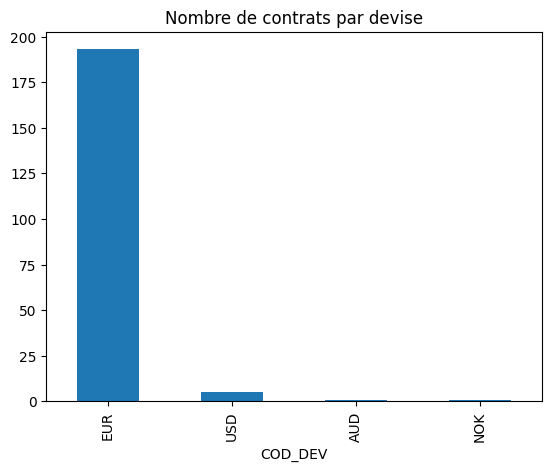

In [85]:
import matplotlib.pyplot as plt   # pour afficher et régler les graphiques

ctr["COD_DEV"].value_counts().plot.bar(title="Nombre de contrats par devise")
plt.show()                        # affiche le graphique

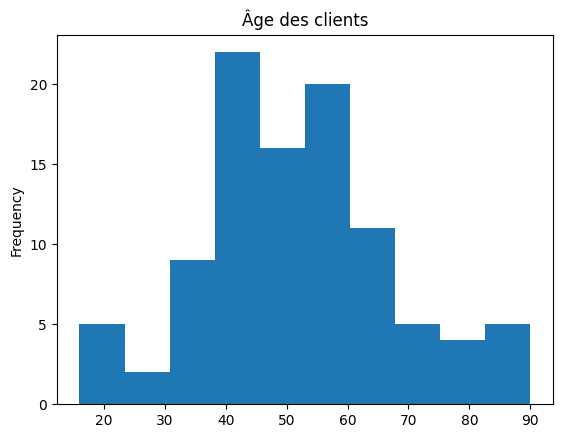

In [86]:
tie["AGE"].plot.hist(bins=10, title="Âge des clients")   # bins = nombre de barres
plt.show()

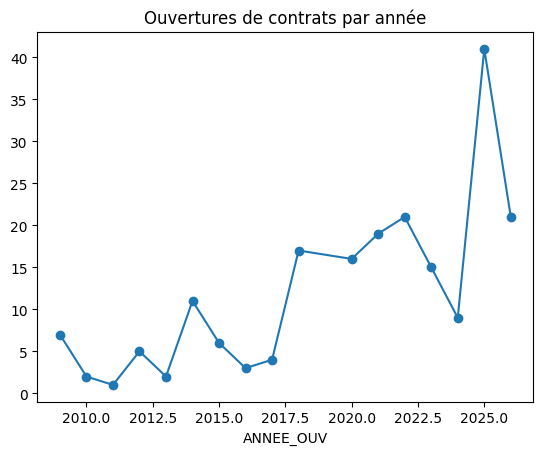

In [87]:
ctr["ANNEE_OUV"].value_counts().sort_index().plot(marker="o", title="Ouvertures de contrats par année")
plt.show()

## 21. Sauvegarder le résultat

- `df.to_csv("fichier.csv", index=False)` → enregistre en CSV (`index=False` évite une colonne 0, 1, 2... en trop)
- `df.to_excel("fichier.xlsx", index=False)` → enregistre en Excel (il faut le module `openpyxl` : `pip install openpyxl`)

In [88]:
contrats_clients.to_csv(
    "contrats_clients.csv",   # nom du fichier créé
    sep=";",                  # même séparateur que nos fichiers d'origine
    index=False,              # ne pas écrire l'index
    encoding="utf-8-sig",     # "utf-8-sig" : les accents s'affichent bien dans Excel
)
print("Fichier contrats_clients.csv créé ✅")

Fichier contrats_clients.csv créé ✅


In [89]:
# Version Excel (enlever le # devant la ligne une fois openpyxl installé)
# contrats_clients.to_excel("contrats_clients.xlsx", index=False)

## 22. 📋 Récapitulatif — les fonctions à retenir

| Thème | Fonctions |
|---|---|
| Lire / écrire | `pd.read_csv`, `pd.read_excel`, `to_csv`, `to_excel` |
| Regarder | `head`, `tail`, `sample`, `shape`, `columns`, `dtypes`, `info`, `describe` |
| Sélectionner | `df["col"]`, `df[["a","b"]]`, `loc`, `iloc` |
| Filtrer | `df[condition]`, `&`, `\|`, `~`, `isin`, `between`, `query`, `str.contains` |
| Trier | `sort_values`, `sort_index`, `nlargest`, `nsmallest` |
| Compter | `value_counts`, `unique`, `nunique`, `count` |
| Manquants | `isna`, `notna`, `fillna`, `dropna` |
| Types | `astype`, `pd.to_datetime`, `pd.to_numeric` |
| Colonnes | `df["new"] = ...`, `np.where`, `map`, `apply`, `pd.cut`, `rename`, `drop` |
| Texte | `str.upper/lower/title`, `str.strip`, `str.len`, `str.split`, `str.replace`, `str[:n]` |
| Dates | `dt.year/month/day`, `dt.days`, `pd.Timestamp.today()` |
| Statistiques | `sum`, `mean`, `median`, `min`, `max`, `std`, `round`, `agg` |
| Regrouper | `groupby` + `count/sum/mean` ou `agg` |
| Croiser | `pivot_table`, `pd.crosstab` |
| Assembler | `pd.merge`, `pd.concat` |
| Doublons | `duplicated`, `drop_duplicates` |
| Index | `set_index`, `reset_index` |
| Graphiques | `plot`, `plot.bar`, `plot.hist`, `plot.pie` |

---

## 🎯 Mini-défis (à vous de jouer !)

Écrivez votre code dans la cellule vide, puis comparez avec la correction.

**Défi 1 :** Combien de clients habitent à Bruxelles (ville `BRUXELLES`) ?

**Défi 2 :** Quel est le solde total (`SLD_CTR`) des contrats **ouverts** ?

**Défi 3 :** Pour chaque ville, combien de contrats possèdent les clients ? Affichez les 5 villes avec le plus de contrats.

In [90]:
# --- votre code ici ---

### ✅ Corrections

In [91]:
# Défi 1 : filtrer la ville puis compter les lignes
nb_bxl = len(adr[adr["NOM_VIL"] == "BRUXELLES"])
print("Défi 1 - Clients à Bruxelles :", nb_bxl)

# Défi 2 : filtrer les contrats ouverts puis faire la somme du solde
solde_ouverts = ctr[ctr["STATUT"] == "OUVERT"]["SLD_CTR"].sum()
print("Défi 2 - Solde total des contrats ouverts :", round(solde_ouverts, 2))

# Défi 3 : on utilise le tableau fusionné de la section 17
top_villes = contrats_clients.groupby("NOM_VIL")["IDT_AC"].count().sort_values(ascending=False).head(5)
print("Défi 3 - Top 5 des villes :")
print(top_villes)

Défi 1 - Clients à Bruxelles : 8
Défi 2 - Solde total des contrats ouverts : -744707.37
Défi 3 - Top 5 des villes :
NOM_VIL
PHNOM PENH          46
BRYE                38
BRUSSEL             27
WANFERCEE-BAULET    23
WONDELGEM           21
Name: IDT_AC, dtype: int64
